# Fulcrum — backtesting LP risk & yield on 6.8 years of real ETH/BTC prices

**Fulcrum** lets traders go long spot ETH/BTC at 5x or 10x with money borrowed from an LP vault.
The two questions every LP (and every judge) should ask:

1. **Will I lose money when the market crashes?** → we replay the 7 worst crashes since 2020 minute by minute.
2. **What do I actually earn?** → we run the vault through every market regime since 2020 — bull, bear, chop.

Everything below is computed from **3.6 million minutes of Binance ETH & BTC prices** (Jan 2020 → Oct 2026)
fed through a minute-by-minute port of our Solidity contracts — same caps, same TWAP oracle, same liquidation
line, same settlement waterfall. Section 9 is a playground: pick your own vault size, traders and parameters.

> Run it yourself: `uv run --with jupyterlab,matplotlib,ipywidgets,numpy jupyter lab sim/fulcrum_backtest.ipynb`
> (first run downloads ~170 monthly price files, cached in `sim/data/`).

In [1]:
%matplotlib inline
import time
from concurrent.futures import ProcessPoolExecutor
from dataclasses import replace

import ipywidgets as W
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import HTML, display

from data import NAMES, load, minute
from model import DAY, YEAR, Demand, Params, Sim
from run import CRASH_DEMAND, CRASHES, crash_job, crash_sim, job

# Palette: validated categorical order (blue, orange, aqua) + reserved status red; recessive greys for chrome.
BLUE, ORANGE, AQUA, YELLOW, RED = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e34948"
INK, INK2, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#8a8984", "#e6e5e0", "#fcfcfb"
SEQ = LinearSegmentedColormap.from_list("seq", [SURFACE, "#cde2fb", "#6da7ec", "#2a78d6", "#184f95", "#0d366b"])
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE, "figure.dpi": 110,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "lines.linewidth": 2, "font.size": 11, "axes.titlesize": 13, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "legend.frameon": False,
})

POOL = ProcessPoolExecutor()
pmap = lambda fn, specs: list(POOL.map(fn, specs))
usd = lambda x: f"${x/1e6:,.2f}M" if abs(x) >= 1e6 else f"${x/1e3:,.1f}k" if abs(x) >= 1e4 else f"${x:,.0f}"
pct = lambda x, d=1: f"{100*x:.{d}f}%"

def kpis(items):
    """Row of stat tiles: (label, value[, note])."""
    tile = ('<div style="background:#fff;border:1px solid #e6e5e0;border-radius:10px;padding:10px 16px;min-width:150px">'
            '<div style="font-size:12px;color:#52514e">{}</div>'
            '<div style="font-size:22px;font-weight:700;color:#0b0b0b;margin-top:2px">{}</div>'
            '<div style="font-size:11px;color:#8a8984">{}</div></div>')
    body = "".join(tile.format(*(list(it) + [""])[:3]) for it in items)
    return HTML(f'<div style="display:flex;flex-wrap:wrap;gap:10px;margin:6px 0 14px">{body}</div>')

def table(header, rows):
    th = "".join(f'<th style="text-align:{"left" if i == 0 else "right"};padding:4px 10px;color:#52514e;'
                 f'border-bottom:1px solid #e6e5e0">{h}</th>' for i, h in enumerate(header))
    tr = "".join("<tr>" + "".join(f'<td style="text-align:{"left" if i == 0 else "right"};padding:4px 10px;'
                                  f'color:#0b0b0b">{c}</td>' for i, c in enumerate(r)) + "</tr>" for r in rows)
    return HTML(f'<table style="border-collapse:collapse;font-size:13px;background:#fff">'
                f'<thead><tr>{th}</tr></thead><tbody>{tr}</tbody></table>')

def times(start, minutes):
    return np.datetime64(start) + np.asarray(minutes).astype("timedelta64[m]")

def with_tiers(p, mu=1.0, lp=1.0):
    """Scale every tier's maintenance margin (mu) and LP profit share (lp)."""
    return replace(p, tiers={k: (m * mu, l * lp, t) for k, (m, l, t) in p.tiers.items()})

def heat(ax, M, xt, yt, fmt, title):
    ax.imshow(M, cmap=SEQ, aspect="auto", vmin=0, vmax=max(M.max(), 1e-9))
    ax.set_xticks(range(len(xt)), xt); ax.set_yticks(range(len(yt)), yt); ax.grid(False); ax.set_title(title)
    for (i, j), v in np.ndenumerate(M):
        ax.text(j, i, fmt(v), ha="center", va="center", fontsize=10,
                color="#fff" if v > 0.55 * M.max() and M.max() > 0 else INK)

## 1 · The data

Binance spot 1-minute closes for ETH and BTC, every minute since 1 Jan 2020 — gap-free, forward-filled across
exchange maintenance. The dotted lines are the seven crashes we replay in section 4.

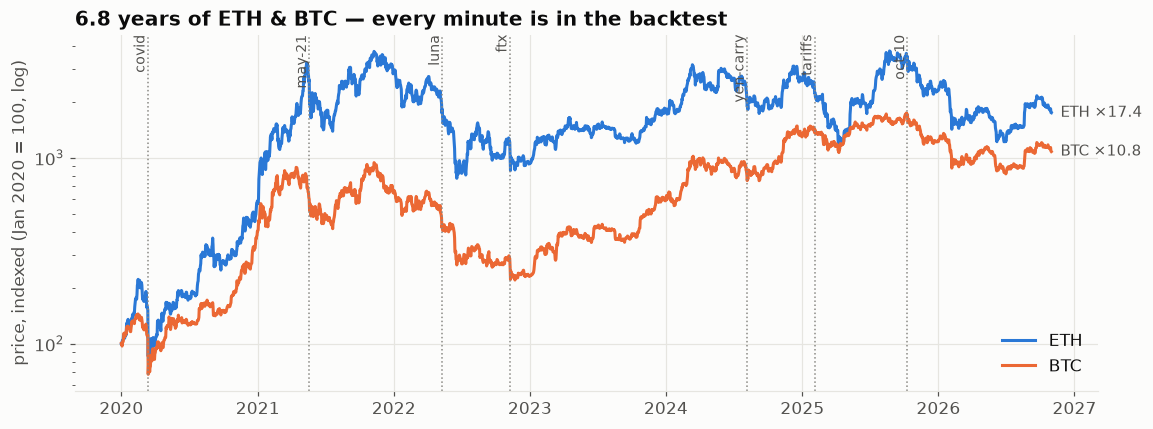

In [2]:
START, END = "2020-01-01", "2026-11-01"
px = load(START, END)
T = px.shape[1]
h1 = px[:, 60:] / px[:, :-60] - 1
display(kpis([
    ("Minutes of history", f"{T:,}", "Jan 2020 → Oct 2026"),
    ("Price points", f"{px.size:,}", "ETH + BTC, 1-minute"),
    ("Worst 1h move — ETH", pct(h1[0].min()), "COVID, 12 Mar 2020"),
    ("Worst 1h move — BTC", pct(h1[1].min())),
    ("Crashes replayed", f"{len(CRASHES)}", "COVID → Oct-10 2025"),
]))

fig, ax = plt.subplots(figsize=(12, 4.2))
d = times(START, np.arange(0, T, DAY))
for k, c in enumerate((BLUE, ORANGE)):
    s = px[k, ::DAY] / px[k, 0] * 100
    ax.plot(d, s, color=c, label=NAMES[k])
    ax.annotate(f"{NAMES[k]} ×{s[-1]/100:.1f}", (d[-1], s[-1]), xytext=(6, 0), textcoords="offset points",
                color=INK2, va="center", fontsize=10)
ax.set_yscale("log"); ax.set_ylabel("price, indexed (Jan 2020 = 100, log)")
for name, day in CRASHES.items():
    ax.axvline(np.datetime64(day), color=MUTED, lw=1, ls=":")
    ax.text(np.datetime64(day), ax.get_ylim()[1], name, rotation=90, va="top", ha="right", fontsize=9, color=INK2)
ax.legend(loc="lower right"); ax.set_title("6.8 years of ETH & BTC — every minute is in the backtest")
plt.show()

## 2 · The engine — our contracts, ported minute by minute

| Contract mechanic | How the sim models it |
|---|---|
| `openPosition` caps | per-asset exposure ≤ 35% of vault, utilisation ≤ 85%, TWAP entry check (1%), unhealthy-at-open check |
| `UniV4TwapOracle` | 10-minute TWAP of pool price; keeper outage ⇒ stale oracle ⇒ **nothing can be priced**; >5 min gap ⇒ 10 min warm-up |
| Liquidation line | `TWAP value ≤ borrowed + rollover debt + maintenance` (4% @5x, 2% @10x) |
| **Swap floor** | liquidation swap reverts if pool pays < TWAP mark − 2% (exits − 1%) ⇒ in a fast crash, positions get **stuck** and retry every minute |
| Pool impact | constant-product pool per asset (default $5M depth, 5 bps fee); our own liquidations move the price; arbs reset it each minute |
| Epochs | 7-day epochs, first one free, then 8% APR rollover debt on borrowed principal |
| `_settle` waterfall | keeper bounty → LP principal → (insurance covers shortfall) → rollover debt 80/20 LP/insurance → penalty to insurance or profit split (90/8/2 @5x, 85/12/3 @10x) |
| `LPVault` | idle USDC optionally earns Morpho yield; share price = cash + borrowed principal |

The model is checked against the contract math (README worked example, waterfall branches, free first epoch,
TWAP-lag bad debt, keeper outage):

In [3]:
import sys
!{sys.executable} test_model.py

ok


## 3 · Headline — a $1M vault, Jan 2020 → Oct 2026

Base case: median margin $2k, 40% pick 10x, median hold 3 days, 70% auto-roll, 30% use stop-losses, and traders
enter **at random** (zero skill). Idle USDC sits in Morpho at 4.5%. The vault goes through COVID, LUNA, FTX and Oct-10.

simulated 3,594,240 minutes in 14s


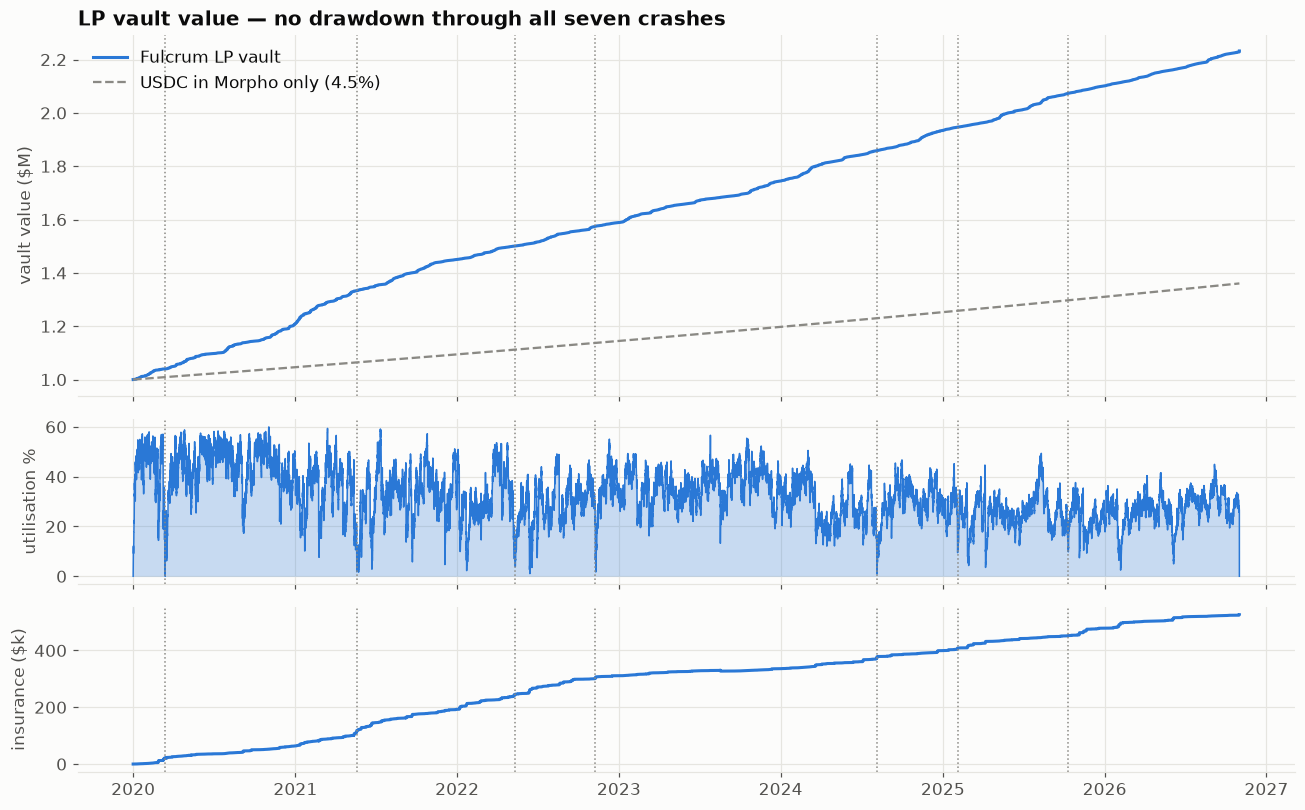

In [4]:
BASE_P, BASE_D = Params(idle_apr=0.045), Demand(per_day=12)
t = time.time()
head = Sim(px, BASE_P, BASE_D, tvl=1e6).run()
r, tr = head.summary(), head.trades()
H = np.array(head.hourly)
baseline = 1e6 * (1 + 0.045 / YEAR) ** (np.arange(len(H)) * 60)
display(kpis([
    ("LP APY (compounded)", pct(r["apy"]), f"vs 4.5% Morpho-only"),
    ("$1M became", usd(H[-1, 0]), f"Morpho-only: {usd(baseline[-1])}"),
    ("Max LP drawdown", pct(r["max_dd"], 2)),
    ("Bad debt hitting LPs", usd(r["bad_debt"]), f"{usd(r['shortfall'])} absorbed by insurance"),
    ("Trading volume", f"{r['volume']:.0f}× TVL / yr", f"{int(r['n_open']):,} positions"),
    ("Liquidated", f"{int(r['n_liq']):,}", pct(r["n_liq"] / r["n_open"], 1) + " of positions"),
    ("Profitable traders", pct(r["win"] if "win" in r else (tr["roi"] > 0).mean(), 0)),
    ("Insurance fund at end", usd(head.ins), "funded by penalties & fees"),
]))
print(f"simulated {T:,} minutes in {time.time() - t:.0f}s")

ht = times(START, np.minimum(np.arange(len(H)) * 60, T - 1))
fig, axs = plt.subplots(3, 1, figsize=(12, 7.5), sharex=True, gridspec_kw=dict(height_ratios=[2.2, 1, 1]))
axs[0].plot(ht, H[:, 0] / 1e6, color=BLUE, label="Fulcrum LP vault")
axs[0].plot(ht, baseline / 1e6, color=MUTED, ls="--", lw=1.5, label="USDC in Morpho only (4.5%)")
axs[0].set_ylabel("vault value ($M)"); axs[0].legend(loc="upper left")
axs[0].set_title("LP vault value — no drawdown through all seven crashes")
axs[1].fill_between(ht, H[:, 1] / H[:, 0] * 100, color=BLUE, alpha=0.25, lw=0)
axs[1].plot(ht, H[:, 1] / H[:, 0] * 100, color=BLUE, lw=1); axs[1].set_ylabel("utilisation %")
axs[2].plot(ht, H[:, 2] / 1e3, color=BLUE); axs[2].set_ylabel("insurance ($k)")
for ax in axs:
    for day in CRASHES.values():
        ax.axvline(np.datetime64(day), color=MUTED, lw=1, ls=":")
plt.tight_layout(); plt.show()

## 4 · Crash replay — the risk question

For each crash we build a book over the 14 days before it (traders keep opening until the caps bind), then run the
crash day and 3 days after. **The insurance fund starts at $0** — it only holds what the protocol itself
collected in those 14 days, so these numbers are conservative.

Four scenarios, from realistic to brutal:

event,date,ETH worst 1h,BTC worst 1h,book at open,liquidations,stuck liq attempts,shortfall,paid by insurance,LP loss
covid,2020-03-12,-26.3%,-24.1%,$206.6k,148,101,"$2,803","$2,803",0.00%
may-21,2021-05-19,-29.8%,-22.4%,$265.0k,183,106,"$1,784","$1,784",0.00%
luna,2022-05-11,-11.4%,-7.6%,$128.4k,153,8,$15,$15,0.00%
ftx,2022-11-08,-11.1%,-8.8%,$695.8k,125,70,$182,$182,0.00%
yen-carry,2024-08-05,-19.8%,-8.1%,$236.8k,137,44,$253,$253,0.00%
tariffs,2025-02-03,-22.9%,-5.2%,$407.2k,86,99,$49,$49,0.00%
oct-10,2025-10-10,-12.9%,-11.0%,$701.1k,61,165,"$1,697","$1,697",0.00%


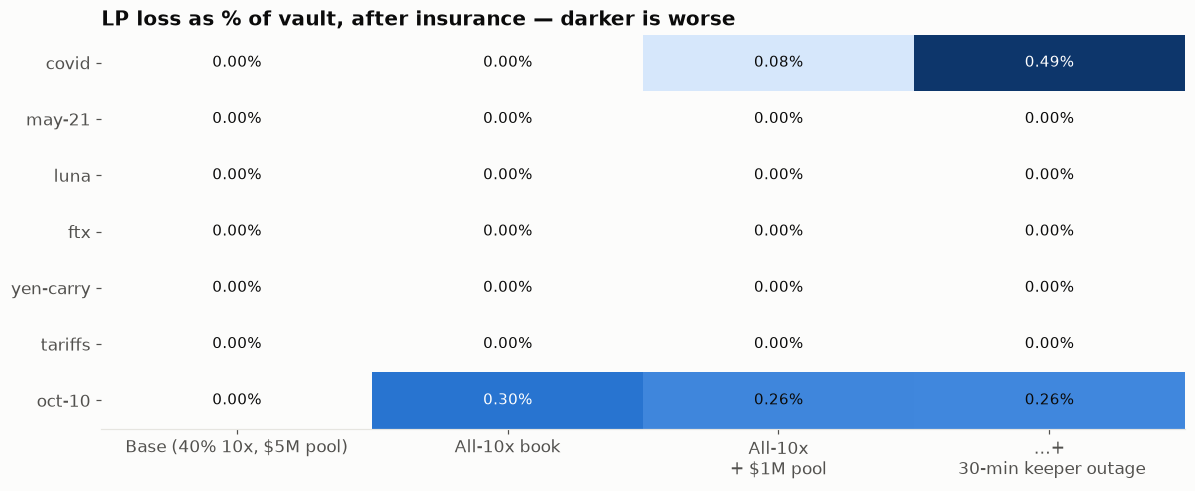

In [5]:
SCEN = {
    "Base (40% 10x, $5M pool)": (Params(), CRASH_DEMAND, 0),
    "All-10x book": (Params(), replace(CRASH_DEMAND, p_10x=1.0), 0),
    "All-10x + $1M pool": (Params(pool_depth=1e6), replace(CRASH_DEMAND, p_10x=1.0), 0),
    "…+ 30-min keeper outage": (Params(pool_depth=1e6), replace(CRASH_DEMAND, p_10x=1.0), 30),
}
specs = [(c, p, d, 1e6, 0.0, o) for (p, d, o) in SCEN.values() for c in CRASHES]
res = pmap(crash_job, specs)
R = {(s, c): res[i * len(CRASHES) + j] for i, s in enumerate(SCEN) for j, c in enumerate(CRASHES)}

rows = []
for c, day in CRASHES.items():
    i = minute(day) - minute(START)
    w = h1[:, max(i - DAY, 0): i + 3 * DAY]
    b = R[("Base (40% 10x, $5M pool)", c)]
    rows.append([c, day, pct(w[0].min()), pct(w[1].min()), usd(b["book"]), int(b["n_liq"]), int(b["blocked_liq"]),
                 usd(b["shortfall"]), usd(b["ins_cover"]), pct(b["bad_debt"] / 1e6, 2)])
display(HTML("<b>Base scenario — what happened in each crash</b>"))
display(table(["event", "date", "ETH worst 1h", "BTC worst 1h", "book at open", "liquidations",
               "stuck liq attempts", "shortfall", "paid by insurance", "LP loss"], rows))

M = np.array([[R[(s, c)]["bad_debt"] / 1e6 * 100 for s in SCEN] for c in CRASHES])
fig, ax = plt.subplots(figsize=(11, 4.6))
heat(ax, M, [s.replace(" + ", "\n+ ").replace("…+", "…+\n") for s in SCEN], list(CRASHES), lambda v: f"{v:.2f}%",
     "LP loss as % of vault, after insurance — darker is worse")
plt.tight_layout(); plt.show()

### Zooming into Oct-10 2025 — why the TWAP matters

The liquidation line is checked against the **10-minute TWAP**, not the live price — that is what makes the
protocol hard to manipulate. The cost: in a fast crash the live price runs ahead of the TWAP. Once the pool sits
more than 2% below the TWAP, the liquidation swap's minimum-out check fails and the position is **stuck** until the
TWAP catches up. Every stuck minute is price falling further below the borrowed principal.

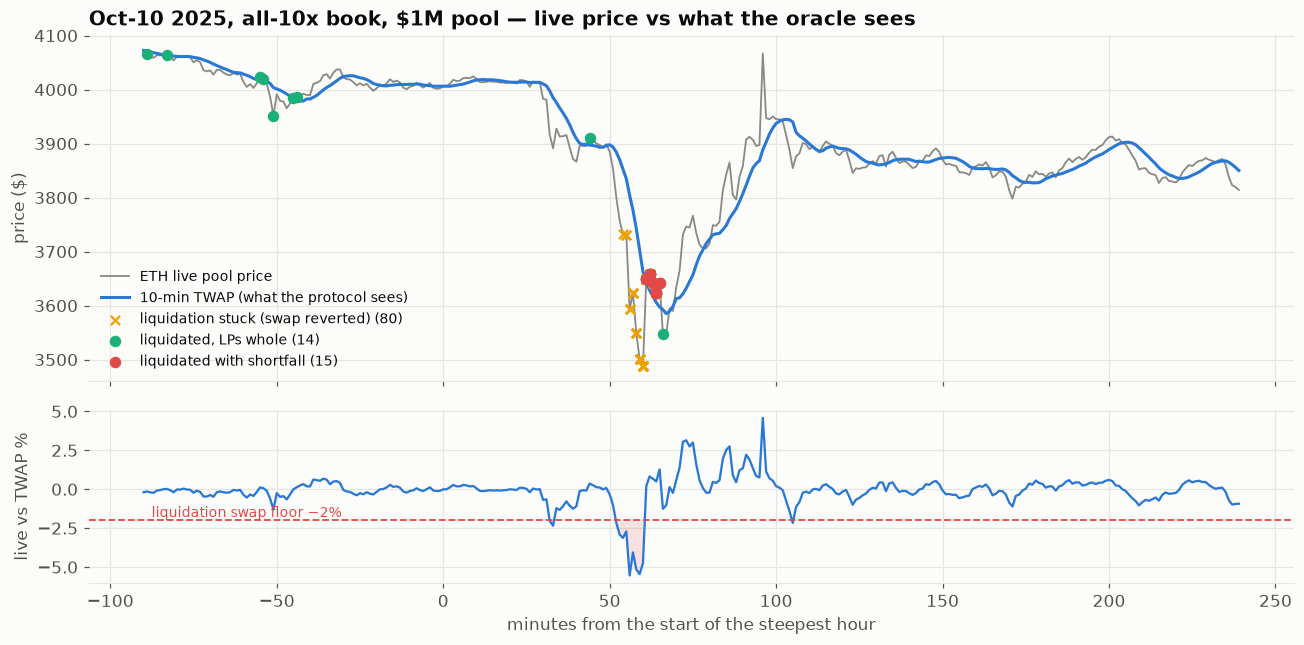

In [6]:
def plot_crash(s, worst, title, p):
    a = int(np.argmin(s.S[:, worst + 60] / s.S[:, worst]))
    lo, hi = max(worst - 90, 0), min(worst + 240, s.T)
    m = np.arange(lo, hi) - worst
    fig, axs = plt.subplots(2, 1, figsize=(12, 6), sharex=True, gridspec_kw=dict(height_ratios=[2, 1]))
    axs[0].plot(m, s.S[a, lo:hi], color=MUTED, lw=1.2, label=f"{NAMES[a]} live pool price")
    axs[0].plot(m, s.tw[a, lo:hi], color=BLUE, label="10-min TWAP (what the protocol sees)")
    ev = {k: [t for t, aa, kk in s.log if aa == a and kk == k and lo <= t < hi] for k in ("liq", "bad", "blocked")}
    for k, c, mk, lab in (("blocked", YELLOW, "x", "liquidation stuck (swap reverted)"),
                          ("liq", AQUA, "o", "liquidated, LPs whole"), ("bad", RED, "o", "liquidated with shortfall")):
        if ev[k]:
            t_ = np.array(ev[k]); axs[0].scatter(t_ - worst, s.S[a, t_], s=36, color=c, marker=mk, zorder=3,
                                                 linewidth=1.5, label=f"{lab} ({len(t_)})")
    axs[0].set_ylabel("price ($)"); axs[0].legend(loc="lower left", fontsize=9); axs[0].set_title(title)
    gap = (s.S[a, lo:hi] / s.tw[a, lo:hi] - 1) * 100
    axs[1].plot(m, gap, color=BLUE, lw=1.5)
    axs[1].axhline(-p.liq_slip * 100, color=RED, ls="--", lw=1.2)
    axs[1].fill_between(m, gap, -p.liq_slip * 100, where=gap < -p.liq_slip * 100, color=RED, alpha=0.15, lw=0)
    axs[1].text(m[0], -p.liq_slip * 100, f"  liquidation swap floor −{p.liq_slip:.0%}", va="bottom", color=RED,
                fontsize=9)
    axs[1].set_ylabel("live vs TWAP %")
    axs[1].set_xlabel("minutes from the start of the steepest hour")
    plt.tight_layout(); plt.show()

p_z = Params(pool_depth=1e6)
s_z, w_z = crash_sim("oct-10", p_z, replace(CRASH_DEMAND, p_10x=1.0))
plot_crash(s_z, w_z, "Oct-10 2025, all-10x book, $1M pool — live price vs what the oracle sees", p_z)

### Stress map — how deep must the pool be?

The single biggest driver of LP loss isn't the size of the crash — it's **pool depth relative to the book** and how
much of the book is at 10x. Each cell is a full replay.

Two things that look odd but are real: **the $0.5M column loses less than $1M** because a shallow pool makes the
1% TWAP entry check reject big opens — on Oct-10 the all-10x book is only $186k at $0.5M depth vs $540k at $1M, so the
entry guard is itself a risk control. A mixed book (≤50% at 10x) loses nothing from **$5M of depth per asset**
(5× the vault). An all-10x book needs about $20M.

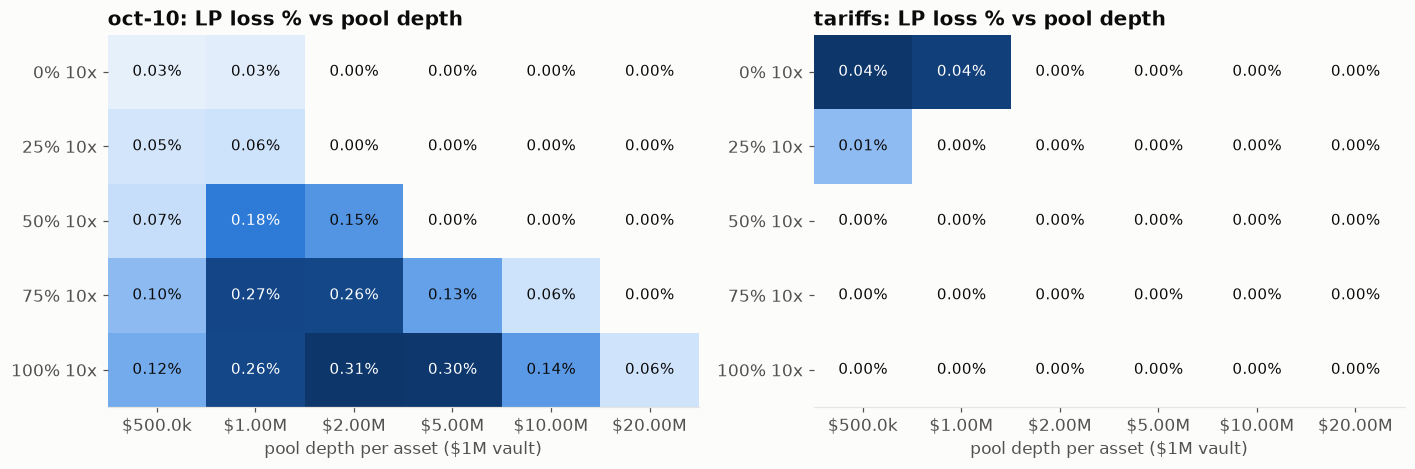

In [7]:
depths, shares = [0.5e6, 1e6, 2e6, 5e6, 1e7, 2e7], [0.0, 0.25, 0.5, 0.75, 1.0]
fig, axs = plt.subplots(1, 2, figsize=(13, 4.4))
for ax, c in zip(axs, ("oct-10", "tariffs")):
    specs = [(c, Params(pool_depth=dp), replace(CRASH_DEMAND, p_10x=sh), 1e6, 0.0, 0) for sh in shares for dp in depths]
    M = np.array([r["bad_debt"] / 1e6 * 100 for r in pmap(crash_job, specs)]).reshape(len(shares), len(depths))
    heat(ax, M, [usd(d) for d in depths], [f"{s:.0%} 10x" for s in shares], lambda v: f"{v:.2f}%",
         f"{c}: LP loss % vs pool depth")
    ax.set_xlabel("pool depth per asset ($1M vault)")
plt.tight_layout(); plt.show()

## 5 · LP yield — volume × how often traders win

The number of traders doesn't matter by itself. Two things do:

1. **Volume** — how much notional traders open, which sets how much LP money is lent out (utilisation).
2. **How often traders win.** Fulcrum LPs are **not the counterparty**: a losing trader loses to the market, not to
   the vault. A winning trader pays LPs 8–12% of the profit. So **LP yield goes up when traders do well** — the
   opposite of GMX-style pools, where LPs earn from trader losses.

First, every year since 2020 with traders who enter at random (zero skill — they only win when the market rises):

year,ETH,BTC,trading volume / yr,utilisation,traders in profit,LP APY,LP bad debt
2020,471%,302%,49× TVL,43%,52%,20.6%,$0
2021,399%,60%,52× TVL,37%,46%,20.3%,$0
2022,-68%,-64%,50× TVL,41%,36%,11.8%,$0
2023,91%,156%,46× TVL,47%,41%,11.8%,$0
2024,46%,121%,49× TVL,44%,45%,14.2%,$0
2025,-11%,-6%,49× TVL,43%,39%,11.5%,$0
2026 YTD,-24%,-11%,47× TVL,45%,38%,9.5%,$0


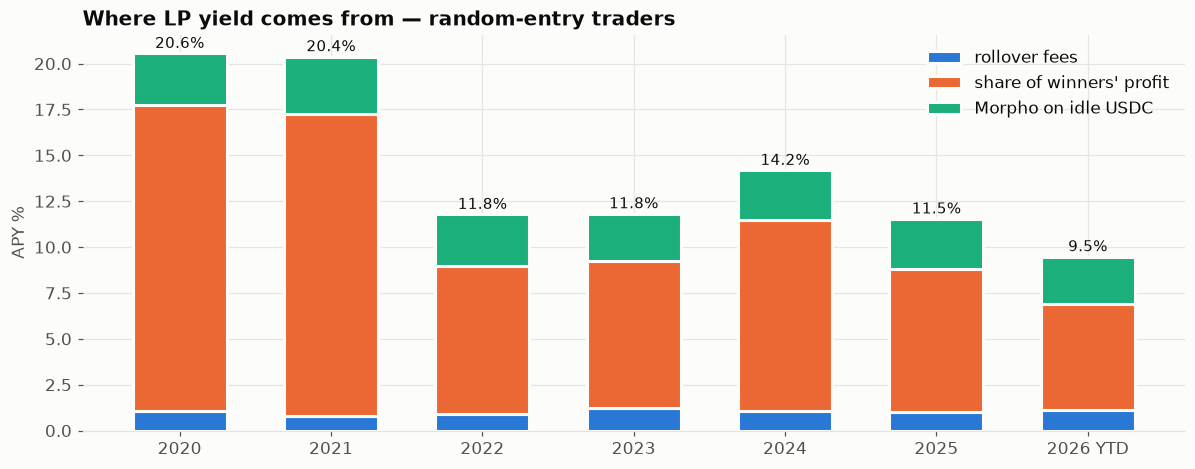

In [8]:
PERIODS = {str(y): (f"{y}-01-01", f"{y+1}-01-01") for y in range(2020, 2026)} | {"2026 YTD": ("2026-01-01", END)}
SEEDS = range(3)
res = pmap(job, [(a, b, BASE_P, BASE_D, 1e6, 0.0, sd) for (a, b) in PERIODS.values() for sd in SEEDS])
Y = {a: res[i * len(SEEDS):(i + 1) * len(SEEDS)] for i, (a, _) in enumerate(PERIODS.values())}
med = lambda a, k: float(np.median([r[k] for r in Y[a]]))

rows = []
for name, (a, b) in PERIODS.items():
    i0, i1 = minute(a) - minute(START), min(minute(b) - minute(START), T) - 1
    rows.append([name, pct(px[0, i1] / px[0, i0] - 1, 0), pct(px[1, i1] / px[1, i0] - 1, 0),
                 f"{med(a, 'volume'):.0f}× TVL", pct(med(a, "util"), 0), pct(med(a, "win"), 0),
                 pct(med(a, "apy")), usd(med(a, "bad_debt"))])
display(table(["year", "ETH", "BTC", "trading volume / yr", "utilisation", "traders in profit", "LP APY",
               "LP bad debt"], rows))

fig, ax = plt.subplots(figsize=(11, 4.4))
names = list(PERIODS); x = np.arange(len(names)); bottom = np.zeros(len(names))
for k, c, lab in (("roll", BLUE, "rollover fees"), ("profit", ORANGE, "share of winners' profit"),
                  ("idle", AQUA, "Morpho on idle USDC")):
    v = np.array([med(a, k) * 100 for a, _ in PERIODS.values()])
    ax.bar(x, v, 0.62, bottom=bottom, color=c, label=lab, edgecolor=SURFACE, linewidth=2)
    bottom += v
for xi, b in zip(x, bottom):
    ax.text(xi, b + 0.3, f"{b:.1f}%", ha="center", fontsize=10, color=INK)
ax.set_xticks(x, names); ax.set_ylabel("APY %"); ax.legend(loc="upper right")
ax.set_title("Where LP yield comes from — random-entry traders")
plt.tight_layout(); plt.show()

### The money map: volume × trader win rate

Now we control both. **Volume** is scaled from ⅓× to 3× base. **Trader skill** is the share of traders who call
the direction right: they skip entries that would be losing at exit and come back later. So volume stays the same
while the win rate goes from ~38% (random) to ~75%. 2025 prices, 2 trader populations per cell.

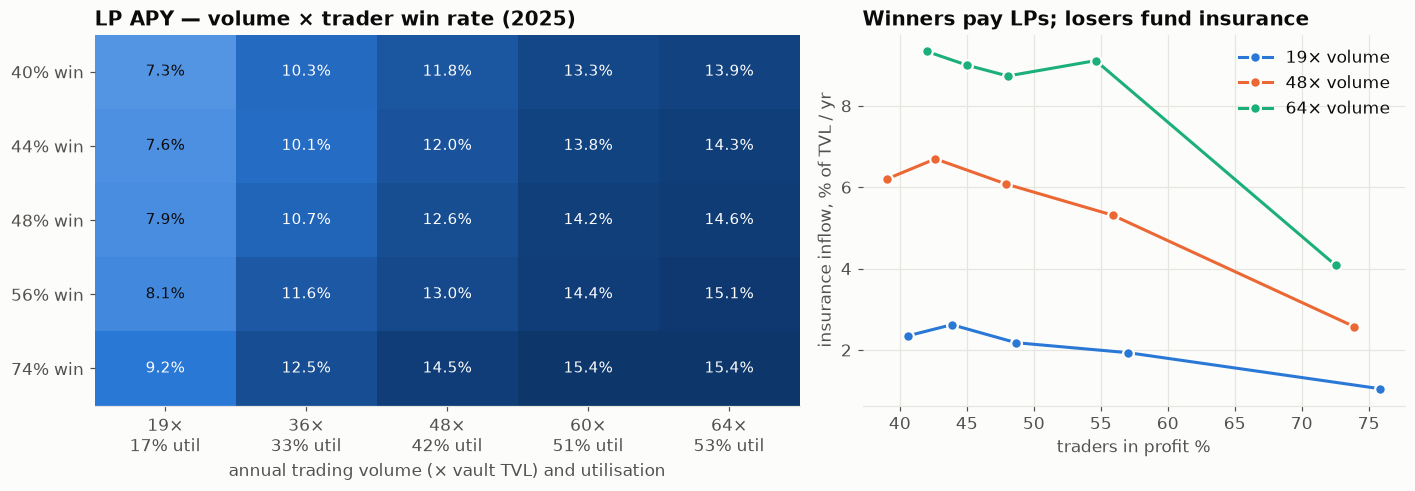

In [9]:
VOL, SKILL = (1 / 3, 2 / 3, 1.0, 2.0, 3.0), (0.0, 0.25, 0.5, 0.75, 1.0)
specs = [("2025-01-01", "2026-01-01", BASE_P, replace(BASE_D, per_day=BASE_D.per_day * v, skill=k), 1e6, 0.0, sd)
         for k in SKILL for v in VOL for sd in (0, 1)]
G = np.array(pmap(job, specs), dtype=object).reshape(len(SKILL), len(VOL), 2)
g = lambda key: np.array([[np.mean([r[key] for r in cell]) for cell in row] for row in G])
apy, win, vol, ins, util = g("apy") * 100, g("win"), g("volume"), g("ins") * 100, g("util")

fig, axs = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw=dict(width_ratios=[1.3, 1]))
heat(axs[0], apy, [f"{v:.0f}×\n{u:.0%} util" for v, u in zip(vol.mean(0), util.mean(0))],
     [f"{w:.0%} win" for w in win.mean(1)], lambda v: f"{v:.1f}%", "LP APY — volume × trader win rate (2025)")
axs[0].set_xlabel("annual trading volume (× vault TVL) and utilisation")
for j, (v, c) in enumerate(zip((0, 2, 4), (BLUE, ORANGE, AQUA))):
    axs[1].plot(win[:, v] * 100, ins[:, v], color=c, marker="o", ms=7, mec=SURFACE, mew=1.5,
                label=f"{vol[:, v].mean():.0f}× volume")
axs[1].set_xlabel("traders in profit %"); axs[1].set_ylabel("insurance inflow, % of TVL / yr")
axs[1].set_title("Winners pay LPs; losers fund insurance"); axs[1].legend()
plt.tight_layout(); plt.show()

display(kpis([
    ("APY, random → skilled traders", f"{apy[0, 2]:.1f}% → {apy[-1, 2]:.1f}%", "at base volume"),
    ("APY, ⅓× → 3× volume", f"{apy[0, 0]:.1f}% → {apy[0, -1]:.1f}%", "random traders"),
    ("Insurance inflow, random → skilled", f"{ins[0, 2]:.1f}% → {ins[-1, 2]:.1f}%", "of TVL per year"),
]))

**What this means:** volume is the big driver of APY. Trader skill comes second, but in the direction LPs want:
the better traders do, the more LPs earn. When traders lose instead, the money goes to the insurance fund
(liquidation penalties), so the protocol takes a cut either way. If excess insurance were routed to LPs (section 8),
LPs would earn whether traders win or lose.

## 6 · Real traders — what 600 Hyperliquid accounts actually do

Everything so far used *synthetic* traders. Here we check that against real ones, using Hyperliquid's free public API:

1. **The whole leaderboard** — 48,000 accounts with their PnL over a day, week, month and all time.
2. **600 random active accounts** — every fill in the last 180 days, rebuilt into **ETH & BTC long positions**
   (flat → long opens a position, back to flat closes it). That's the slice of Hyperliquid that maps onto Fulcrum.

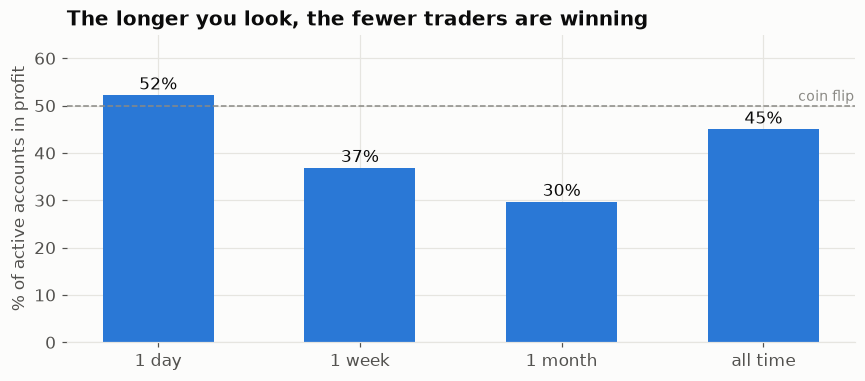

In [10]:
import hl
BOARD = hl.board()
WIN = (("day", "1 day"), ("week", "1 week"), ("month", "1 month"), ("allTime", "all time"))
share = [np.mean([r[f"{w}_pnl"] > 0 for r in BOARD if r[f"{w}_vlm"] > 0]) for w, _ in WIN]
n_act = [sum(r[f"{w}_vlm"] > 0 for r in BOARD) for w, _ in WIN]
pnl = np.sort([r["allTime_pnl"] for r in BOARD])[::-1]
top1 = pnl[: len(pnl) // 100].sum() / pnl[pnl > 0].sum()

display(kpis([("Accounts on the leaderboard", f"{len(BOARD):,}"),
              ("In profit over the last month", pct(share[2], 0), f"of {n_act[2]:,} active accounts"),
              ("Profits taken by the top 1%", pct(top1, 0), "all time")]))

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(range(4), np.array(share) * 100, 0.55, color=BLUE)
for i, v in enumerate(share):
    ax.text(i, v * 100 + 1.2, pct(v, 0), ha="center", color=INK)
ax.axhline(50, color=MUTED, lw=1, ls="--"); ax.text(3.45, 51, "coin flip", color=MUTED, fontsize=9, ha="right")
ax.set_xticks(range(4), [l for _, l in WIN]); ax.set_ylim(0, 65); ax.set_ylabel("% of active accounts in profit")
ax.set_title("The longer you look, the fewer traders are winning")
plt.tight_layout(); plt.show()

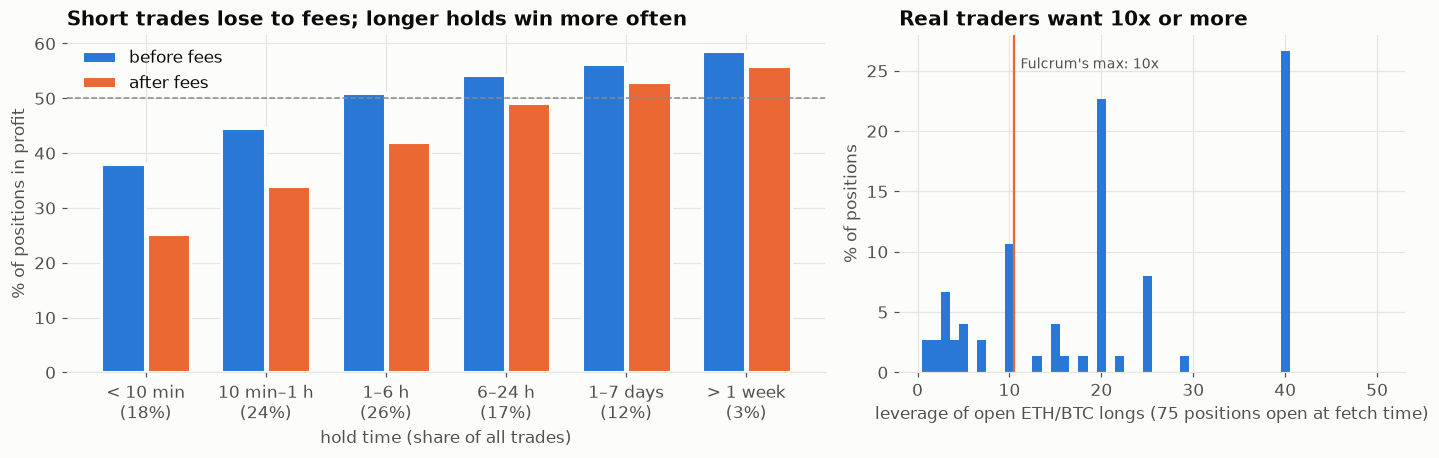

In [11]:
HL = hl.load(600)
H = hl.table(HL)
m = H["closed"] & np.isin(H["coin"], ["ETH", "BTC"])
LEV = np.array([(x[1], x[3]) for x in hl.leverage(HL) if x[0] in ("ETH", "BTC") and x[4]])
first, last = (np.datetime64(int(v), "ms").astype("datetime64[D]") for v in (H["t_open"][m].min(), H["t_open"][m].max()))

display(kpis([
    ("ETH/BTC long positions", f"{m.sum():,}", f"{len(set(H['user'][m]))} traders · {first} → {last}"),
    ("In profit before fees", pct(np.mean(H["pnl"][m] > 0), 0), "≈ a coin flip: no edge on direction"),
    ("In profit after fees", pct(np.mean(H["net"][m] > 0), 0), "fees turn ~1 in 5 winners into losers"),
    ("Median hold", f"{np.median(H['hold_h'][m]):.1f} h", f"our synthetic traders: {BASE_D.hold_median_days:.0f} days"),
    ("Liquidated", pct(H["liq"][m].mean(), 1), "at Hyperliquid leverage"),
    ("Open longs above 10x", pct((LEV[:, 0] > 10).mean(), 0), f"median {np.median(LEV[:, 0]):.0f}x"),
]))

BUCKETS = ((0, 1/6, "< 10 min"), (1/6, 1, "10 min–1 h"), (1, 6, "1–6 h"), (6, 24, "6–24 h"), (24, 168, "1–7 days"),
           (168, 1e9, "> 1 week"))
fig, axs = plt.subplots(1, 2, figsize=(13, 4.3), gridspec_kw=dict(width_ratios=[1.5, 1]))
x = np.arange(len(BUCKETS))
k = [m & (H["hold_h"] >= lo) & (H["hold_h"] < hi) for lo, hi, _ in BUCKETS]
for off, key, c, lab in ((-0.19, "pnl", BLUE, "before fees"), (0.19, "net", ORANGE, "after fees")):
    axs[0].bar(x + off, [np.mean(H[key][b] > 0) * 100 for b in k], 0.36, color=c, label=lab, edgecolor=SURFACE, lw=2)
axs[0].axhline(50, color=MUTED, lw=1, ls="--")
axs[0].set_xticks(x, [f"{l}\n({b.sum() / m.sum():.0%})" for (*_, l), b in zip(BUCKETS, k)])
axs[0].set_xlabel("hold time (share of all trades)"); axs[0].set_ylabel("% of positions in profit"); axs[0].legend(loc="upper left")
axs[0].set_title("Short trades lose to fees; longer holds win more often")
lv = np.clip(LEV[:, 0], 1, 50)
axs[1].hist(lv, bins=np.arange(0.5, 51.5, 1), color=BLUE, weights=np.full(len(lv), 100 / len(lv)))
axs[1].axvline(10.5, color=ORANGE, lw=1.5)
axs[1].text(11.2, axs[1].get_ylim()[1] * 0.9, "Fulcrum's max: 10x", color=INK2, fontsize=9)
axs[1].set_xlabel(f"leverage of open ETH/BTC longs ({len(lv)} positions open at fetch time)"); axs[1].set_ylabel("% of positions")
axs[1].set_title("Real traders want 10x or more")
plt.tight_layout(); plt.show()

**What real traders look like:** on direction they're a coin flip (~49% up before fees), and fees push that to ~40%.
That's the same as our *zero-skill* synthetic traders, so the earlier sections didn't flatter the traders. The big
difference is **hold time** — hours, not days — and most real traders want **10x or more**.

### Replaying these exact trades through a Fulcrum vault

Each real ETH/BTC long goes through our contract model at its **real entry minute and real hold time**, against
Binance prices. Hyperliquid accounts are far bigger than one vault, so all sizes are scaled by a single factor to a
$1M vault (whale trades that would move the pool more than 1% still fail the entry check, as they would on-chain).
Tier: 10x for 80% of trades, matching the leverage chart. Same window, compared with our synthetic traders.

In [12]:
RS, RE = "2026-05-11", "2026-11-01"
HOLDS = ((0, "all real trades"), (1, "real, held ≥ 1 h"), (6, "real, held ≥ 6 h"), (24, "real, held ≥ 1 day"))
REP = pmap(hl.replay_job, [(h, RS, RE, BASE_P, 47.0) for h, _ in HOLDS])
_s = Sim(load(RS, RE), BASE_P, BASE_D, 1e6).run(); _t = _s.trades(); _d = _t["st"] >= 2
SYN = _s.summary() | dict(win=(_t["roi"][_d] > 0).mean(), liq_rate=(_t["st"][_d] == 3).mean())

rows = [[lab, f"{r['volume']:.0f}×", pct(r["util"], 0), pct(r["win"], 0), pct(r["liq_rate"], 1),
         pct(r["roll"]), pct(r["profit"]), pct(r["idle"]), f"<b>{pct(r['apy'])}</b>", usd(r["bad_debt"])]
        for (_, lab), r in zip(HOLDS, REP)]
rows.append(["synthetic traders (sections 3–5)", f"{SYN['volume']:.0f}×", pct(SYN["util"], 0), pct(SYN["win"], 0),
             pct(SYN["liq_rate"], 1), pct(SYN["roll"]), pct(SYN["profit"]), pct(SYN["idle"]), f"<b>{pct(SYN['apy'])}</b>",
             usd(SYN["bad_debt"])])
display(table(["traders", "volume / yr", "utilisation", "in profit", "liquidated", "rollover", "profit share",
               "Morpho", "LP APY", "LP bad debt"], rows))

traders,volume / yr,utilisation,in profit,liquidated,rollover,profit share,Morpho,LP APY,LP bad debt
all real trades,42×,10%,32%,0.6%,0.3%,1.4%,4.1%,5.9%,$0
"real, held ≥ 1 h",37×,16%,39%,1.1%,0.5%,1.9%,3.8%,6.4%,$0
"real, held ≥ 6 h",28×,20%,42%,1.8%,0.6%,2.8%,3.7%,7.2%,$0
"real, held ≥ 1 day",17×,20%,43%,3.9%,0.6%,2.4%,3.7%,6.8%,$0
synthetic traders (sections 3–5),47×,46%,36%,2.9%,1.0%,6.2%,2.5%,9.9%,$0


**What this tells us:**

- **Safety holds with real traders.** $0 LP bad debt, and fewer liquidations than on Hyperliquid, because Fulcrum
  caps leverage at 10x.
- **Yield depends on how long traders hold.** Real Hyperliquid traders are in and out within hours. The first
  week of borrowing is free, so they pay almost no rollover. Their small price moves also mean small profits to
  share. LPs earn roughly 6–7% instead of ~10% for the same window, and most of that is the idle-USDC yield.
- **Fulcrum's natural users are swing traders**, who hold for days and want spot exposure without funding rates.
  Hyperliquid's scalpers aren't. If we do attract scalpers, a small **opening fee** paid to LPs is the lever:
  it charges exactly the trades that currently pay LPs nothing.

## 7 · The trader side — is this a fair game?

Same 6.8-year headline run, from the traders' point of view. LPs only earn a cut of *winning* trades and never
take the other side of losing ones — so the protocol needs winners to pay LPs.

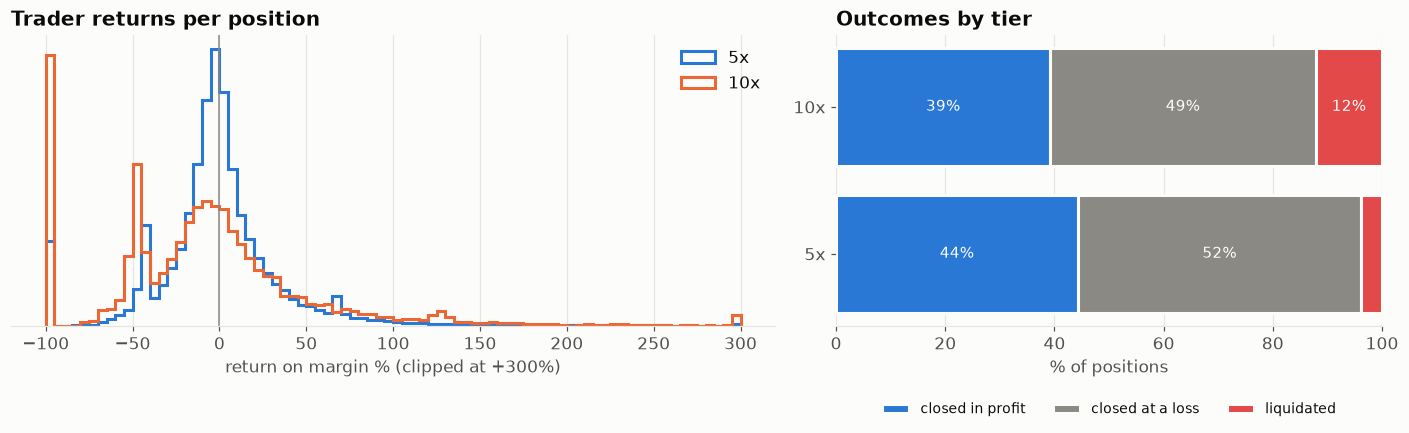

In [13]:
done = tr["st"] >= 2
rows_k = []
for tier in (5, 10):
    m = done & (tr["tier"] == tier)
    rows_k += [(f"{tier}x liquidated", pct((tr["st"][m] == 3).mean(), 0)),
               (f"{tier}x in profit", pct((tr["roi"][m] > 0).mean(), 0))]
hold = (tr["t_exit"][done] - tr["t_open"][done]) / DAY
display(kpis([("Positions", f"{done.sum():,}"), ("Median hold", f"{np.median(hold):.1f} days"),
              ("Paid out to traders", usd(head.L["trader_out"]))] + rows_k))

fig, axs = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw=dict(width_ratios=[1.4, 1]))
bins = np.linspace(-1, 3, 81)
for tier, c in ((5, BLUE), (10, ORANGE)):
    m = done & (tr["tier"] == tier)
    axs[0].hist(np.clip(tr["roi"][m], -1, 3) * 100, bins=bins * 100, histtype="step", lw=2, color=c,
                density=True, label=f"{tier}x")
axs[0].axvline(0, color=MUTED, lw=1); axs[0].set_xlabel("return on margin % (clipped at +300%)")
axs[0].set_yticks([]); axs[0].legend(); axs[0].set_title("Trader returns per position")
for row, tier in enumerate((5, 10)):
    m = done & (tr["tier"] == tier)
    parts = [((tr["st"][m] == 2) & (tr["roi"][m] > 0)).mean(), ((tr["st"][m] == 2) & (tr["roi"][m] <= 0)).mean(),
             (tr["st"][m] == 3).mean()]
    left = 0
    for v, c, lab in zip(parts, (BLUE, MUTED, RED), ("closed in profit", "closed at a loss", "liquidated")):
        axs[1].barh(row, v * 100, left=left, color=c, edgecolor=SURFACE, linewidth=2, label=lab if row == 0 else None)
        if v > 0.06:
            axs[1].text(left + v * 50, row, f"{v:.0%}", ha="center", va="center", color="#fff", fontsize=10)
        left += v * 100
axs[1].set_yticks([0, 1], ["5x", "10x"]); axs[1].set_xlim(0, 100); axs[1].set_xlabel("% of positions")
axs[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=3, fontsize=9); axs[1].set_title("Outcomes by tier")
plt.tight_layout(); plt.show()

## 8 · Which levers matter — and which are dangerous

One knob at a time, low and high, everything else at base. Left: LP APY in 2025 at base volume. Right: LP loss
in the Oct-10 crash with an all-10x book on a $1M pool (our stressed case).

**Caveat:** demand is held fixed. In reality a higher fee or a bigger LP cut scares traders away — so the APY gain
from "charge more" levers is an upper bound.

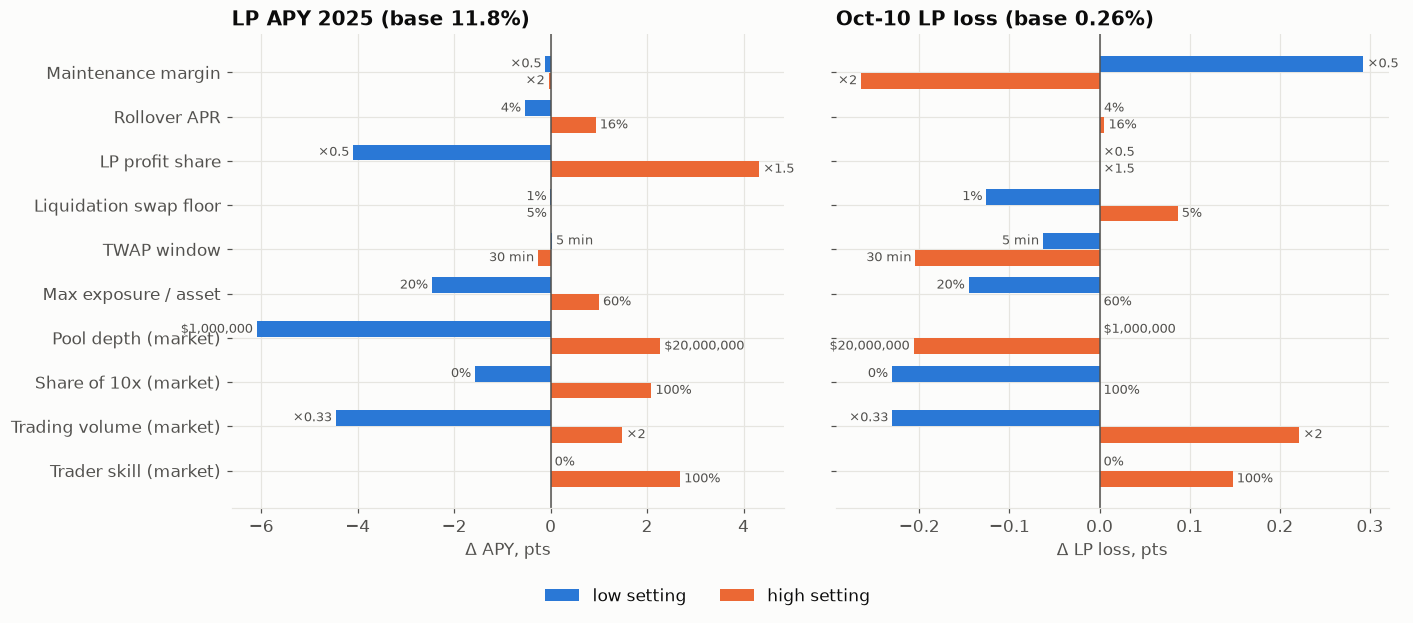

In [14]:
LEVERS = [  # (label, low, high, value format, apply(p, d, v) -> (p, d))
    ("Maintenance margin", 0.5, 2.0, "×{:g}", lambda p, d, v: (with_tiers(p, mu=v), d)),
    ("Rollover APR", 0.04, 0.16, "{:.0%}", lambda p, d, v: (replace(p, rollover_apr=v), d)),
    ("LP profit share", 0.5, 1.5, "×{:g}", lambda p, d, v: (with_tiers(p, lp=v), d)),
    ("Liquidation swap floor", 0.01, 0.05, "{:.0%}", lambda p, d, v: (replace(p, liq_slip=v), d)),
    ("TWAP window", 5, 30, "{} min", lambda p, d, v: (replace(p, twap_min=v), d)),
    ("Max exposure / asset", 0.2, 0.6, "{:.0%}", lambda p, d, v: (replace(p, max_exposure=v), d)),
    ("Pool depth (market)", 1e6, 2e7, "${:,.0f}", lambda p, d, v: (replace(p, pool_depth=v), d)),
    ("Share of 10x (market)", 0.0, 1.0, "{:.0%}", lambda p, d, v: (p, replace(d, p_10x=v))),
    ("Trading volume (market)", 1 / 3, 2.0, "×{:.2g}", lambda p, d, v: (p, replace(d, per_day=v * d.per_day))),
    ("Trader skill (market)", 0.0, 1.0, "{:.0%}", lambda p, d, v: (p, replace(d, skill=v))),
]
CP, CD = Params(pool_depth=1e6), replace(CRASH_DEMAND, p_10x=1.0)
ys, cs = [], []
for _, lo, hi, _, f in LEVERS:
    for v in (lo, hi):
        p, d = f(BASE_P, BASE_D, v); ys += [("2025-01-01", "2026-01-01", p, d, 1e6, 0.0, sd) for sd in (0, 1)]
        p, d = f(CP, CD, v); cs.append(("oct-10", p, d, 1e6, 0.0, 0))
ys += [("2025-01-01", "2026-01-01", BASE_P, BASE_D, 1e6, 0.0, sd) for sd in (0, 1)]
cs.append(("oct-10", CP, CD, 1e6, 0.0, 0))
yr, cr = pmap(job, ys), pmap(crash_job, cs)
apy = np.array([np.mean([yr[2 * k]["apy"], yr[2 * k + 1]["apy"]]) for k in range(len(yr) // 2)]) * 100
loss = np.array([r["bad_debt"] / 1e6 * 100 for r in cr])
base_apy, base_loss = apy[-1], loss[-1]

fig, axs = plt.subplots(1, 2, figsize=(13, 5.6), sharey=True)
for ax, vals, base, title, unit in ((axs[0], apy, base_apy, f"LP APY 2025 (base {base_apy:.1f}%)", "Δ APY, pts"),
                                    (axs[1], loss, base_loss, f"Oct-10 LP loss (base {base_loss:.2f}%)", "Δ LP loss, pts")):
    for k, (lab, lo, hi, vf, _) in enumerate(LEVERS):
        for j, (v, c) in enumerate(((lo, BLUE), (hi, ORANGE))):
            dlt = vals[2 * k + j] - base
            ax.barh(k + (j - 0.5) * 0.38, dlt, 0.36, color=c, label=(["low setting", "high setting"][j] if k == 0 else None))
            ax.text(dlt, k + (j - 0.5) * 0.38, f" {vf.format(v)} ", va="center", ha="left" if dlt >= 0 else "right",
                    fontsize=8.5, color=INK2)
    ax.axvline(0, color=INK2, lw=1); ax.set_title(title); ax.set_xlabel(unit)
axs[0].set_yticks(range(len(LEVERS)), [l[0] for l in LEVERS]); axs[0].invert_yaxis()
fig.legend(*axs[0].get_legend_handles_labels(), loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.02))
plt.tight_layout(rect=(0, 0.05, 1, 1)); plt.show()

### What we'd tune, and what we'd leave alone

| Lever | Verdict | Why (from the runs above) |
|---|---|---|
| **Maintenance margin** | ✅ Raise it | ×2 removes the entire stressed Oct-10 LP loss at almost no APY cost. ×0.5 doubles it. The cheapest risk lever we have; the cost is that traders get liquidated a little earlier. |
| **Max exposure / asset** | ✅ Tie it to pool depth | What matters is the book relative to on-chain liquidity, not to vault TVL (see the stress map). The cap should follow the pool. |
| **Insurance routing** | ✅ Cap the fund | In the 6.8-year run the fund ends at ~$525k but pays out only ~$19k. Capping it at a few % of TVL and sending the excess to LPs would add several points of APY. |
| **Rollover APR** | ⚪ Minor | Median hold is under 7 days and the first epoch is free, so 16% vs 8% adds only ~1 pt. |
| **Liquidation swap floor** | ⚠️ Don't widen | 5% makes LP loss worse (it accepts worse fills); 1% is slightly better but blocks more liquidations in thin pools. 2% is a reasonable balance. |
| **TWAP window** | ⚠️ Keep at 10 min | Both 5 and 30 min shave a little off the Oct-10 loss, so there's no clear crash case for moving it. A shorter window is easier to manipulate, and a longer one is slower to react; the model sees neither. |
| **LP profit share** | ❌ Trap | ×1.5 shows +4 pts APY, but it taxes the winners who pay LPs in the first place. Demand is fixed in this model, so the real gain is smaller and probably negative. |

## 9 · Playground — run your own vault

Set the vault, the traders and the protocol knobs, pick a market period, hit **Run**. *Trader skill* = share of traders who call the direction right (0 = random entry). A one-year run takes
a few seconds; *Full history* about 15s. (Static preview below the controls uses the defaults.)

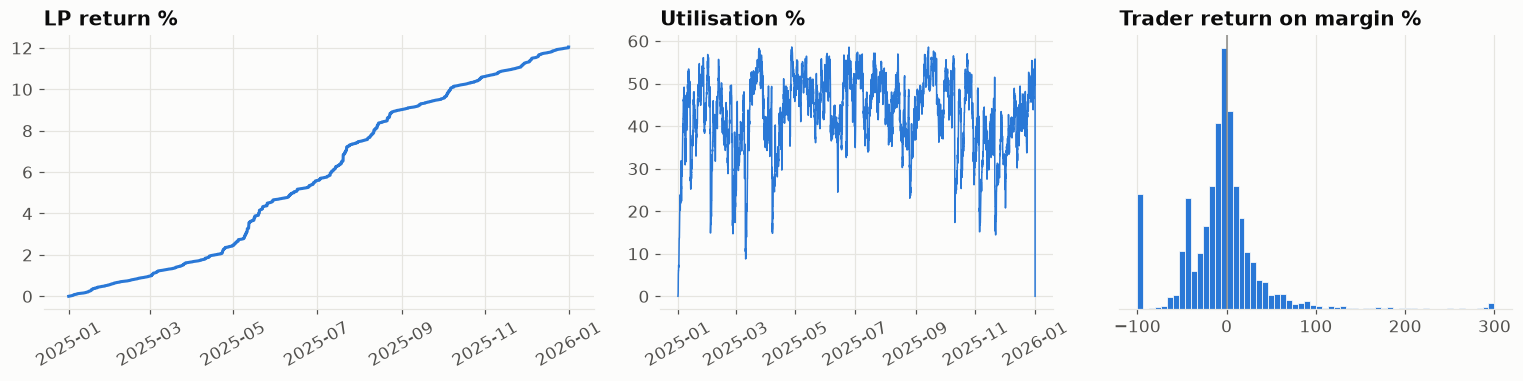

In [15]:
PERIODS_UI = PERIODS | {"Full history 2020→2026": (START, END)}
sty = dict(style={"description_width": "150px"}, layout=W.Layout(width="360px"))
ctl = dict(
    period=W.Dropdown(options=list(PERIODS_UI), value="2025", description="Market period", **sty),
    tvl=W.FloatLogSlider(value=1e6, base=10, min=5, max=8, step=0.1, description="Vault TVL $", **sty),
    per_day=W.FloatSlider(value=12, min=1, max=60, step=1, description="Trade arrivals / day", **sty),
    skill=W.FloatSlider(value=0, min=0, max=1, step=0.05, description="Trader skill", **sty),
    margin=W.FloatLogSlider(value=2000, base=10, min=2, max=5, step=0.1, description="Median margin $", **sty),
    p_10x=W.FloatSlider(value=0.4, min=0, max=1, step=0.05, description="Share choosing 10x", **sty),
    hold=W.FloatLogSlider(value=3, base=10, min=-1, max=1.5, step=0.05, description="Median hold (days)", **sty),
    p_auto=W.FloatSlider(value=0.7, min=0, max=1, step=0.05, description="Auto-roll share", **sty),
    p_sl=W.FloatSlider(value=0.3, min=0, max=1, step=0.05, description="Stop-loss users", **sty),
    idle=W.FloatSlider(value=0.045, min=0, max=0.1, step=0.005, readout_format=".1%", description="Morpho APR", **sty),
    roll=W.FloatSlider(value=0.08, min=0, max=0.3, step=0.01, readout_format=".0%", description="Rollover APR", **sty),
    mu=W.FloatSlider(value=1, min=0.5, max=3, step=0.25, description="Maintenance ×", **sty),
    lp=W.FloatSlider(value=1, min=0.25, max=2, step=0.25, description="LP profit share ×", **sty),
    expo=W.FloatSlider(value=0.35, min=0.1, max=1, step=0.05, readout_format=".0%", description="Max exposure/asset", **sty),
    depth=W.FloatLogSlider(value=5e6, base=10, min=5, max=8, step=0.1, description="Pool depth $", **sty),
)

def playground(period, tvl, per_day, skill, margin, p_10x, hold, p_auto, p_sl, idle, roll, mu, lp, expo, depth):
    a, b = PERIODS_UI[period]
    p = with_tiers(Params(idle_apr=idle, rollover_apr=roll, max_exposure=expo, pool_depth=depth), mu=mu, lp=lp)
    d = Demand(per_day=per_day, skill=skill, margin_median=margin, p_10x=p_10x, hold_median_days=hold, p_auto=p_auto, p_sl=p_sl)
    s = Sim(load(a, b), p, d, tvl=tvl).run(); r, t_ = s.summary(), s.trades()
    done = t_["st"] >= 2
    display(kpis([("LP APY", pct(r["apy"])), ("Trading volume", f"{r['volume']:.0f}× TVL / yr"),
                  ("Avg utilisation", pct(r["util"], 0)), ("Max drawdown", pct(r["max_dd"], 2)),
                  ("Bad debt to LPs", usd(r["bad_debt"])), ("Insurance at end", usd(s.ins)),
                  ("Positions", f"{int(r['n_open']):,}", f"{int(r['rej_cap']):,} turned away by caps"),
                  ("Traders in profit", pct((t_["roi"][done] > 0).mean() if done.any() else 0, 0)),
                  ("Liquidated", pct((t_["st"][done] == 3).mean() if done.any() else 0, 0))]))
    H = np.array(s.hourly); ht = times(a, np.minimum(np.arange(len(H)) * 60, s.T - 1))
    fig, axs = plt.subplots(1, 3, figsize=(14, 3.6), gridspec_kw=dict(width_ratios=[1.4, 1, 1]))
    axs[0].plot(ht, H[:, 0] / tvl * 100 - 100, color=BLUE); axs[0].set_title("LP return %")
    axs[0].tick_params(axis="x", labelrotation=30)
    axs[1].plot(ht, H[:, 1] / H[:, 0] * 100, color=BLUE, lw=1); axs[1].set_title("Utilisation %")
    axs[1].tick_params(axis="x", labelrotation=30)
    if done.any():
        axs[2].hist(np.clip(t_["roi"][done], -1, 3) * 100, bins=60, color=BLUE, edgecolor=SURFACE, linewidth=0.5)
    axs[2].axvline(0, color=MUTED, lw=1); axs[2].set_title("Trader return on margin %"); axs[2].set_yticks([])
    plt.tight_layout(); plt.show()

out = W.Output()
btn = W.Button(description="Run", button_style="primary", icon="play")
def _go(_):
    with out:
        out.clear_output(wait=True); playground(**{k: w.value for k, w in ctl.items()})
btn.on_click(_go)
display(W.VBox([W.GridBox(list(ctl.values()), layout=W.Layout(grid_template_columns="repeat(2, 380px)")), btn, out]))
playground(**{k: w.value for k, w in ctl.items()})

### Crash lab — break it yourself

Pick a crash, make the book as aggressive as you like, drain the pool, knock the keeper offline.

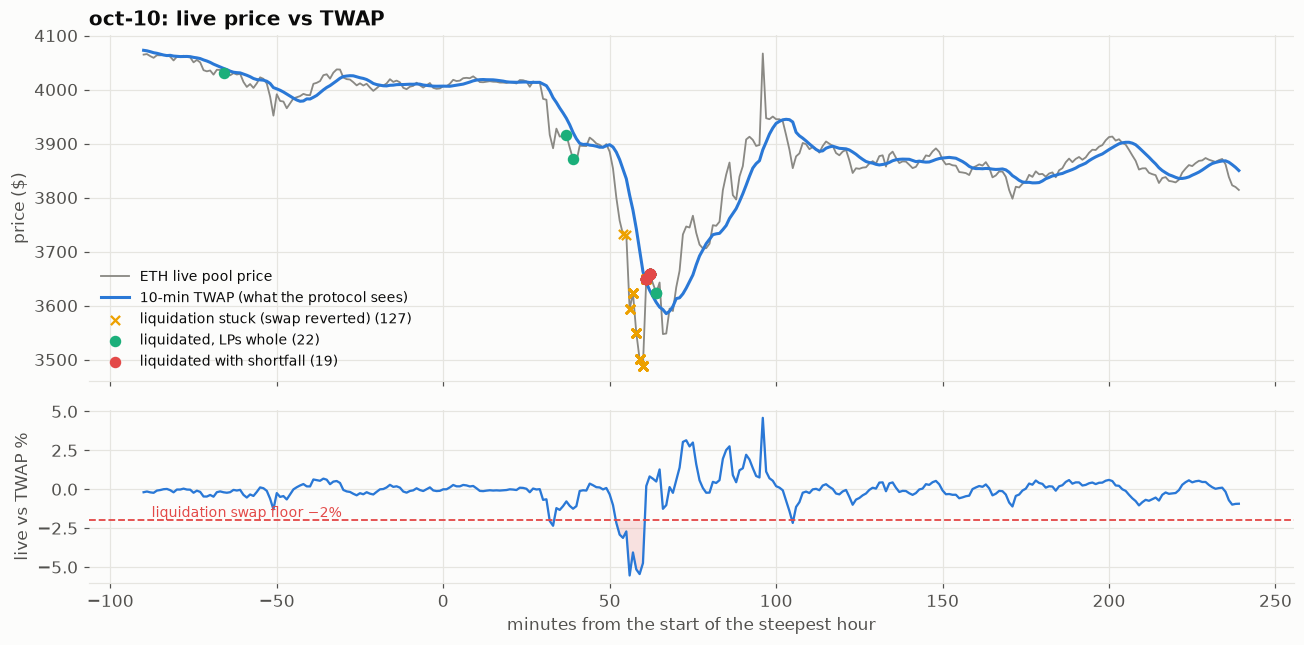

In [16]:
cl = dict(
    event=W.Dropdown(options=list(CRASHES), value="oct-10", description="Crash", **sty),
    p_10x=W.FloatSlider(value=0.4, min=0, max=1, step=0.05, description="Share choosing 10x", **sty),
    depth=W.FloatLogSlider(value=5e6, base=10, min=5, max=8, step=0.1, description="Pool depth $", **sty),
    outage=W.IntSlider(value=0, min=0, max=120, step=5, description="Keeper outage (min)", **sty),
    insurance=W.FloatSlider(value=0, min=0, max=100_000, step=5_000, description="Insurance seed $", **sty),
    liq_slip=W.FloatSlider(value=0.02, min=0.005, max=0.1, step=0.005, readout_format=".1%", description="Liq. swap floor", **sty),
    twap=W.IntSlider(value=10, min=1, max=60, description="TWAP window (min)", **sty),
    mu=W.FloatSlider(value=1, min=0.5, max=3, step=0.25, description="Maintenance ×", **sty),
)

def crash_lab(event, p_10x, depth, outage, insurance, liq_slip, twap, mu):
    p = with_tiers(Params(pool_depth=depth, liq_slip=liq_slip, twap_min=twap), mu=mu)
    s, w = crash_sim(event, p, replace(CRASH_DEMAND, p_10x=p_10x), 1e6, insurance, outage)
    r = s.summary()
    display(kpis([("LP loss", pct(r["bad_debt"] / 1e6, 2), usd(r["bad_debt"])), ("Liquidations", f"{int(r['n_liq'])}"),
                  ("Exits with shortfall", f"{int(r['n_bad'])}", "liquidations + stop-losses"), ("Stuck attempts", f"{int(r['blocked_liq'])}"),
                  ("Shortfall", usd(r["shortfall"])), ("Paid by insurance", usd(r["ins_cover"]))]))
    plot_crash(s, w, f"{event}: live price vs TWAP", replace(p, outages=()))

out2 = W.Output()
btn2 = W.Button(description="Replay crash", button_style="danger", icon="bolt")
def _go2(_):
    with out2:
        out2.clear_output(wait=True); crash_lab(**{k: w.value for k, w in cl.items()})
btn2.on_click(_go2)
display(W.VBox([W.GridBox(list(cl.values()), layout=W.Layout(grid_template_columns="repeat(2, 380px)")), btn2, out2]))
crash_lab(**{k: w.value for k, w in cl.items()})

## Method & limits

- **Prices:** Binance 1-minute closes. The Uniswap pool is assumed to track them (arbitrage), with a constant-product
  depth parameter for slippage. Intra-minute wicks and real v4 tick liquidity are not modelled yet.
- **Traders:** sections 3–5 use a synthetic population (Poisson arrivals, lognormal size & hold time, random entry
  timing). Section 6 replays 180 days of real Hyperliquid ETH/BTC longs from 600 random accounts. Fills carry no
  leverage, so tiers are drawn from live open positions; sizes are scaled to the vault.
- **LPs:** no deposits or withdrawals, so the exit queue, solvency gate and bonus pot are not exercised here.
- **Validation:** unit checks against the contract math above; next step is replaying these crash paths through
  the real contracts on a Foundry fork and diffing the results.

Source: `sim/model.py` (engine) · `sim/data.py` (prices) · `sim/hl.py` (Hyperliquid traders) · `sim/run.py` (CLI: `uv run sim/run.py crash|yield`).